**Healthcare Analysis for Doctor visits**

**Introduction:**
      
Healthcare data analytics is the process of examining healthcare-related data to identify patterns, trends and useful information. It helps us understand how demographic, socioeconomic and health-related factors are associated with the use of medical services.

This project focuses on analyzing a healthcare dataset containing information about doctor visits, age, gender, income, illness, health status, chronic conditions and insurance coverage. Python libraries such as Pandas, NumPy, Matplotlib and Seaborn are used to clean, analyze and visualize the data.

**Objectives:**



*   To understand the structure and characteristics of the healthcare dataset.
*   To identify missing values and examine the quality of the data.

*   To analyze the distribution of individual variables.

*   To compare doctor visits across demographic and health-related groups.

*   To examine relationships between doctor visits, income, illness and insurance coverage.

*   To study multiple variables together to identify combined patterns.
*   To present meaningful observations through data visualization.


*   To provide recommendations based on the results of the analysis.







In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv(r"/content/1776250375-P2-Healthcare Analytics for Doctor Visits.csv")

In [3]:
df.shape

(5190, 13)

In [4]:
df.head()

,Unnamed: 0,visits,gender,age,income,illness,reduced,health,private,freepoor,freerepat,nchronic,lchronic
0,1,1,female,0.19,0.55,1,4,1,yes,no,no,no,no
1,2,1,female,0.19,0.45,1,2,1,yes,no,no,no,no
2,3,1,male,0.19,0.90,3,0,0,no,no,no,no,no
3,4,1,male,0.19,0.15,1,0,0,no,no,no,no,no
4,5,1,male,0.19,0.45,2,5,1,no,no,no,yes,no


In [5]:
df.tail()

,Unnamed: 0,visits,gender,age,income,illness,reduced,health,private,freepoor,freerepat,nchronic,lchronic
5185,5186,0,female,0.22,0.55,0,0,0,no,no,no,no,no
5186,5187,0,male,0.27,1.30,0,0,1,no,no,no,no,no
5187,5188,0,female,0.37,0.25,1,0,1,no,no,yes,no,no
5188,5189,0,female,0.52,0.65,0,0,0,no,no,no,no,no
5189,5190,0,male,0.72,0.25,0,0,0,no,no,yes,no,no


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5190 entries, 0 to 5189
Data columns (total 13 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  5190 non-null   int64  
 1   visits      5190 non-null   int64  
 2   gender      5190 non-null   object 
 3   age         5190 non-null   float64
 4   income      5190 non-null   float64
 5   illness     5190 non-null   int64  
 6   reduced     5190 non-null   int64  
 7   health      5190 non-null   int64  
 8   private     5190 non-null   object 
 9   freepoor    5190 non-null   object 
 10  freerepat   5190 non-null   object 
 11  nchronic    5190 non-null   object 
 12  lchronic    5190 non-null   object 
dtypes: float64(2), int64(5), object(6)
memory usage: 527.2+ KB


In [7]:
df.describe()

,Unnamed: 0,visits,age,income,illness,reduced,health
count,5190.000000,5190.000000,5190.000000,5190.000000,5190.000000,5190.000000,5190.000000
mean,2595.500000,0.301734,0.406385,0.583160,1.431985,0.861850,1.217534
std,1498.368279,0.798134,0.204782,0.368907,1.384152,2.887628,2.124266
min,1.000000,0.000000,0.190000,0.000000,0.000000,0.000000,0.000000
25%,1298.250000,0.000000,0.220000,0.250000,0.000000,0.000000,0.000000
50%,2595.500000,0.000000,0.320000,0.550000,1.000000,0.000000,0.000000
75%,3892.750000,0.000000,0.620000,0.900000,2.000000,0.000000,2.000000
max,5190.000000,9.000000,0.720000,1.500000,5.000000,14.000000,12.000000


In [8]:
df.columns

Index(['Unnamed: 0', 'visits', 'gender', 'age', 'income', 'illness', 'reduced',
       'health', 'private', 'freepoor', 'freerepat', 'nchronic', 'lchronic'],
      dtype='object')

In [9]:
for col in df.select_dtypes(include="object").columns:
    print("\n", col)
    print(df[col].value_counts())


 gender
gender
female    2702
male      2488
Name: count, dtype: int64

 private
private
no     2892
yes    2298
Name: count, dtype: int64

 freepoor
freepoor
no     4968
yes     222
Name: count, dtype: int64

 freerepat
freerepat
no     4099
yes    1091
Name: count, dtype: int64

 nchronic
nchronic
no     3098
yes    2092
Name: count, dtype: int64

 lchronic
lchronic
no     4585
yes     605
Name: count, dtype: int64


data cleaning

In [10]:
df = df.drop(columns=["Unnamed: 0"])

In [11]:
print(df.isnull().sum())

visits       0
gender       0
age          0
income       0
illness      0
reduced      0
health       0
private      0
freepoor     0
freerepat    0
nchronic     0
lchronic     0
dtype: int64


In [12]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 1320


In [13]:
df = df.drop_duplicates()

statistics

In [14]:
print("Average doctor visits:", df["visits"].mean().round(2))
print("Maximum doctor visits:", df["visits"].max())
print("Minimum doctor visits:", df["visits"].min())
print("Median doctor visits:", df["visits"].median())
print("Standard deviation:", df["visits"].std())

Average doctor visits: 0.39
Maximum doctor visits: 9
Minimum doctor visits: 0
Median doctor visits: 0.0
Standard deviation: 0.8994332361564801


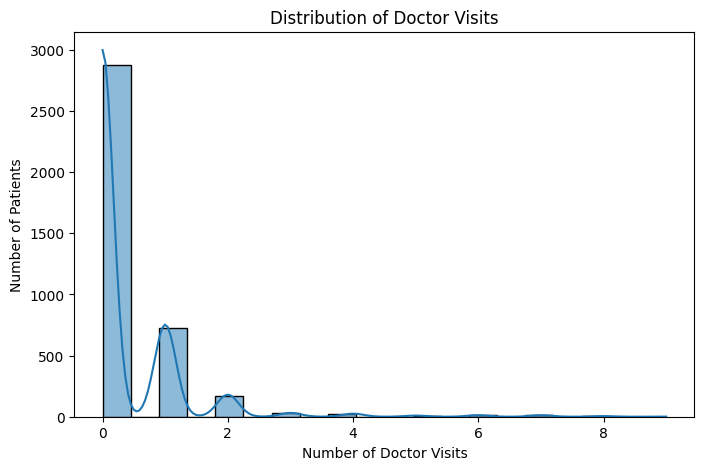

In [15]:
plt.figure(figsize=(8,5))

sns.histplot(df["visits"], bins=20, kde=True)

plt.title("Distribution of Doctor Visits")
plt.xlabel("Number of Doctor Visits")
plt.ylabel("Number of Patients")

plt.show()

In [16]:
gender_visits = df.groupby("gender")["visits"].mean()

print(gender_visits)

gender
female    0.449710
male      0.319645
Name: visits, dtype: float64


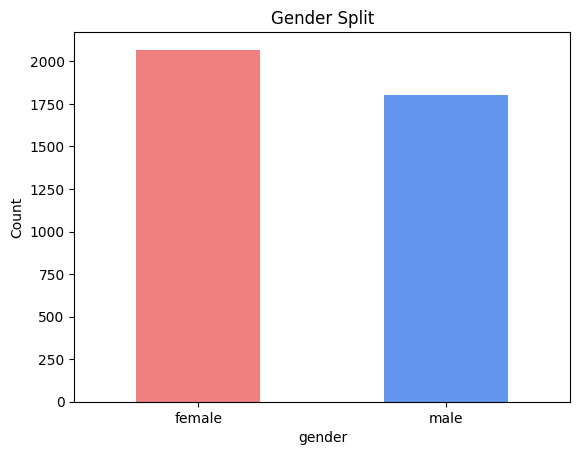

In [17]:
df['gender'].value_counts().plot(kind='bar', color=['lightcoral', 'cornflowerblue'])
plt.title('Gender Split')
plt.ylabel('Count')
plt.xticks(rotation=0)
plt.show()

In [18]:
print(df["age"].unique())

[0.19 0.22 0.27 0.32 0.37 0.42 0.47 0.52 0.57 0.62 0.67 0.72]


In [19]:
age_visits = df.groupby("age")["visits"].mean()

print(age_visits)

age
0.19    0.285455
0.22    0.294776
0.27    0.349869
0.32    0.299180
0.37    0.274809
0.42    0.350877
0.47    0.308176
0.52    0.469388
0.57    0.441296
0.62    0.424710
0.67    0.502203
0.72    0.638489
Name: visits, dtype: float64


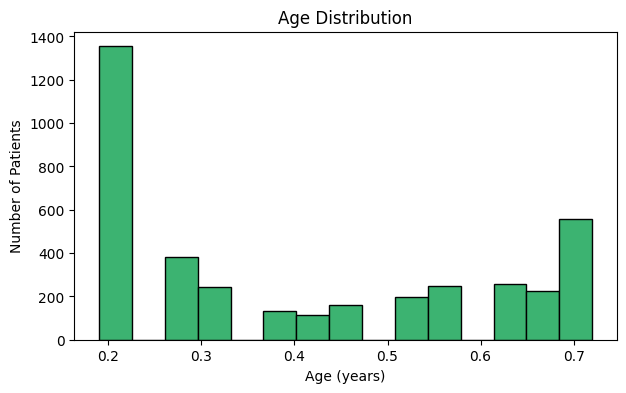

In [20]:
# age distribution
plt.figure(figsize=(7,4))
plt.hist(df['age'], bins=15, color='mediumseagreen', edgecolor='black')
plt.title('Age Distribution')
plt.xlabel('Age (years)')
plt.ylabel('Number of Patients')
plt.show()

In [21]:
income_visits = df.groupby("income")["visits"].mean()

print(income_visits)

income
0.00    0.408451
0.01    0.485714
0.06    0.207792
0.15    0.400000
0.25    0.568750
0.35    0.448370
0.45    0.368421
0.55    0.342105
0.65    0.325513
0.75    0.335423
0.90    0.293103
1.10    0.242308
1.30    0.335821
1.50    0.318436
Name: visits, dtype: float64


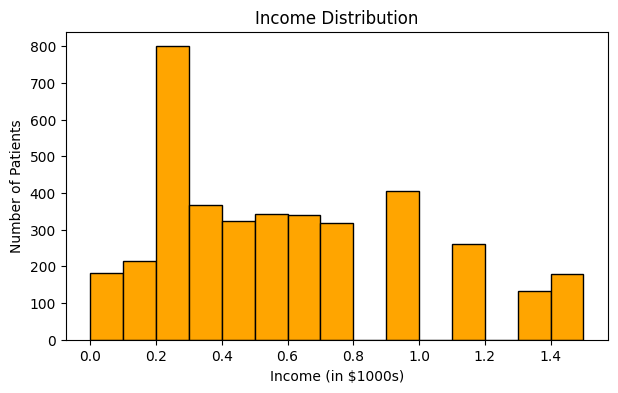

In [22]:
# income distribution
plt.figure(figsize=(7,4))
plt.hist(df['income'], bins=15, color='orange', edgecolor='black')
plt.title('Income Distribution')
plt.xlabel('Income (in $1000s)')
plt.ylabel('Number of Patients')
plt.show()

gender
female    0.449710
male      0.319645
Name: visits, dtype: float64


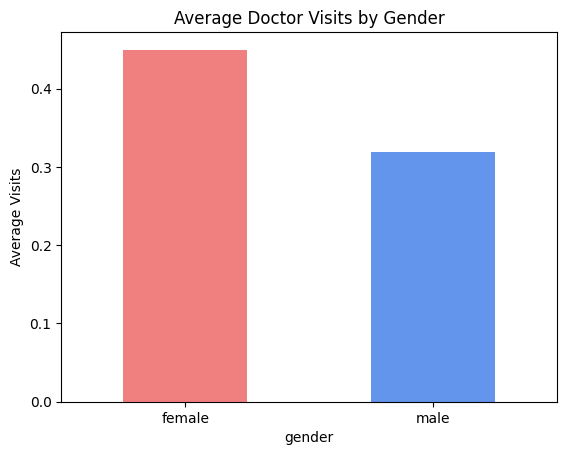

In [23]:
# average visits by gender
avg_by_gender = df.groupby('gender')['visits'].mean()
print(avg_by_gender)

avg_by_gender.plot(kind='bar', color=['lightcoral', 'cornflowerblue'])
plt.title('Average Doctor Visits by Gender')
plt.ylabel('Average Visits')
plt.xticks(rotation=0)
plt.show()

age
0.19    0.285455
0.22    0.294776
0.27    0.349869
0.32    0.299180
0.37    0.274809
0.42    0.350877
0.47    0.308176
0.52    0.469388
0.57    0.441296
0.62    0.424710
0.67    0.502203
0.72    0.638489
Name: visits, dtype: float64


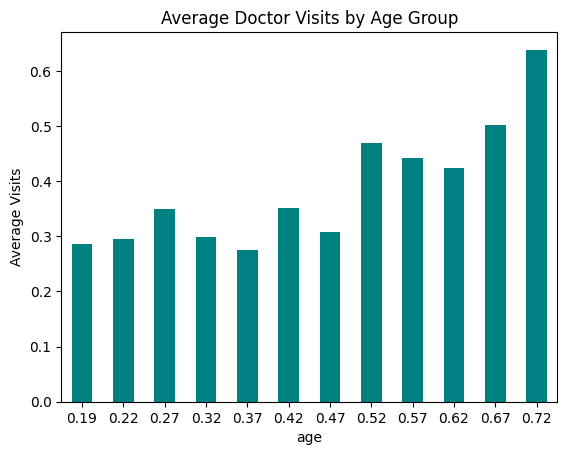

In [24]:
# average visits by age group
avg_by_age = df.groupby('age', observed=True)['visits'].mean()
print(avg_by_age)

avg_by_age.plot(kind='bar', color='teal')
plt.title('Average Doctor Visits by Age Group')
plt.ylabel('Average Visits')
plt.xticks(rotation=0)
plt.show()


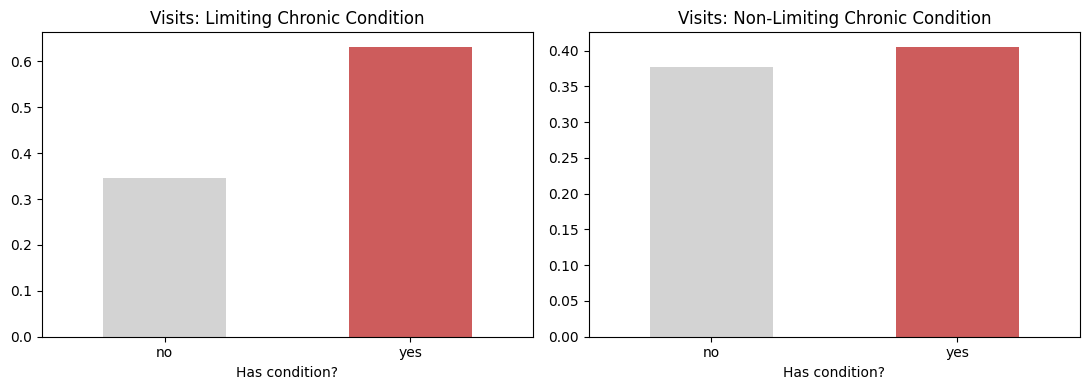

In [25]:
# does having a chronic illness change how often people visit the doctor?
avg_lchronic = df.groupby('lchronic')['visits'].mean()
avg_nchronic = df.groupby('nchronic')['visits'].mean()

fig, axes = plt.subplots(1, 2, figsize=(11,4))
avg_lchronic.plot(kind='bar', ax=axes[0], color=['lightgrey', 'indianred'])
axes[0].set_title('Visits: Limiting Chronic Condition')
axes[0].set_xlabel('Has condition?')
axes[0].tick_params(axis='x', rotation=0)

avg_nchronic.plot(kind='bar', ax=axes[1], color=['lightgrey', 'indianred'])
axes[1].set_title('Visits: Non-Limiting Chronic Condition')
axes[1].set_xlabel('Has condition?')
axes[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

private
no     0.403257
yes    0.372615
Name: visits, dtype: float64


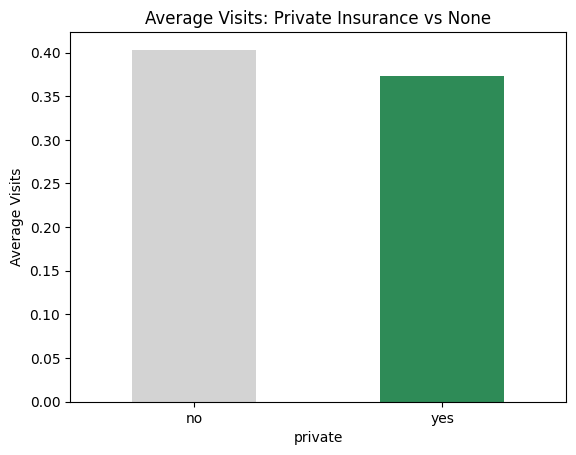

In [26]:
# does private insurance make a difference?
avg_by_private = df.groupby('private')['visits'].mean()
print(avg_by_private)

avg_by_private.plot(kind='bar', color=['lightgrey', 'seagreen'])
plt.title('Average Visits: Private Insurance vs None')
plt.ylabel('Average Visits')
plt.xticks(rotation=0)
plt.show()


         visits   age  income  illness  reduced  health
visits     1.00  0.12   -0.08     0.19     0.40    0.15
age        0.12  1.00   -0.20     0.17     0.11    0.00
income    -0.08 -0.20    1.00    -0.13    -0.05   -0.10
illness    0.19  0.17   -0.13     1.00     0.19    0.31
reduced    0.40  0.11   -0.05     0.19     1.00    0.25
health     0.15  0.00   -0.10     0.31     0.25    1.00


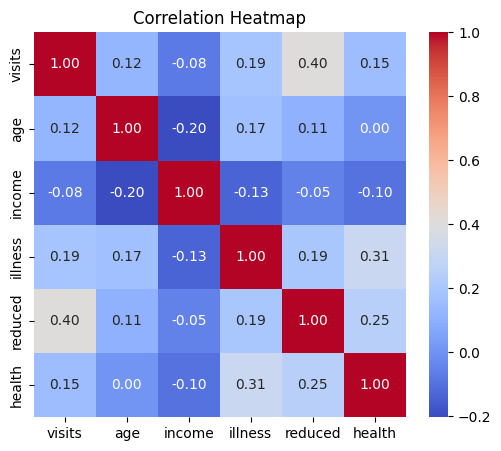

In [27]:
numeric_cols = ['visits', 'age', 'income', 'illness', 'reduced', 'health']
corr = df[numeric_cols].corr()
print(corr.round(2))

plt.figure(figsize=(6,5))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()


In [28]:
free_poor_avg = df[df['freepoor'] == 'yes']['visits'].mean()
free_repat_avg = df[df['freerepat'] == 'yes']['visits'].mean()
no_free_avg = df[(df['freepoor'] == 'no') & (df['freerepat'] == 'no')]['visits'].mean()

print("Free insurance (low income):", round(free_poor_avg, 3))
print("Free insurance (veteran/repat):", round(free_repat_avg, 3))
print("No free government insurance:", round(no_free_avg, 3))

Free insurance (low income): 0.18
Free insurance (veteran/repat): 0.611
No free government insurance: 0.345


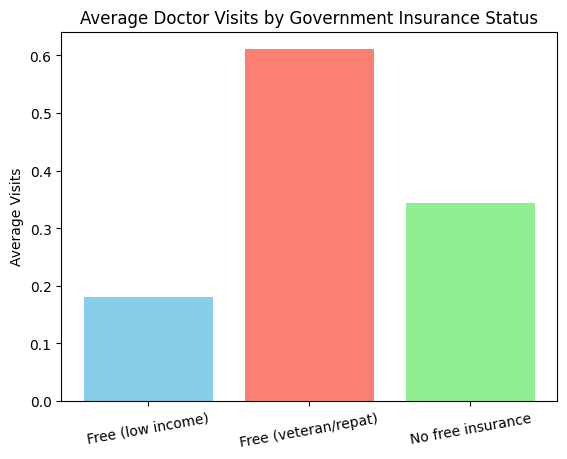

In [29]:
segments = ['Free (low income)', 'Free (veteran/repat)', 'No free insurance']
values = [free_poor_avg, free_repat_avg, no_free_avg]

plt.bar(segments, values, color=['skyblue', 'salmon', 'lightgreen'])
plt.title('Average Doctor Visits by Government Insurance Status')
plt.ylabel('Average Visits')
plt.xticks(rotation=10)
plt.show()

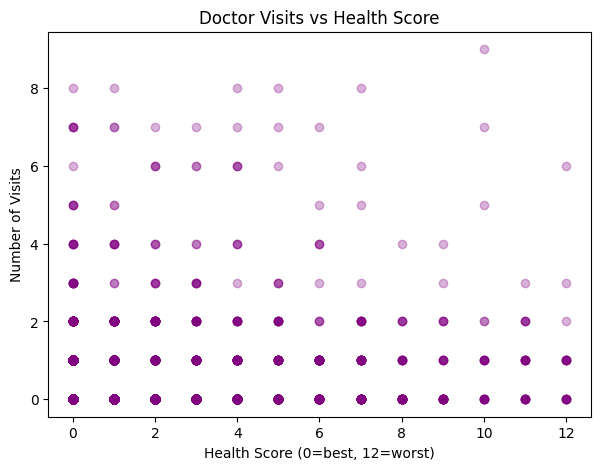

In [30]:
# relationship between self-reported health score and visits
# (higher health score = worse health, according to the data dictionary)
plt.figure(figsize=(7,5))
plt.scatter(df['health'], df['visits'], alpha=0.3, color='purple')
plt.title('Doctor Visits vs Health Score')
plt.xlabel('Health Score (0=best, 12=worst)')
plt.ylabel('Number of Visits')
plt.show()


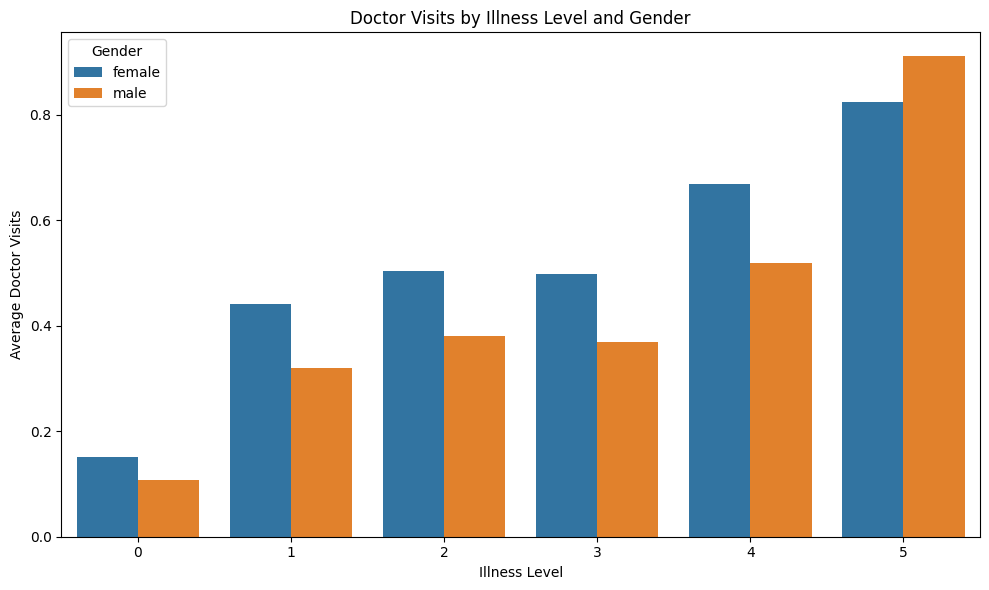

In [31]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=df,
    x="illness",
    y="visits",
    hue="gender",
    errorbar=None
)

plt.title("Doctor Visits by Illness Level and Gender")
plt.xlabel("Illness Level")
plt.ylabel("Average Doctor Visits")
plt.legend(title="Gender")
plt.tight_layout()
plt.show()

Average Doctor Visits by Gender and Illness


illness,0,1,2,3,4,5
gender,,,,,,
female,0.15,0.44,0.50,0.50,0.67,0.82
male,0.11,0.32,0.38,0.37,0.52,0.91


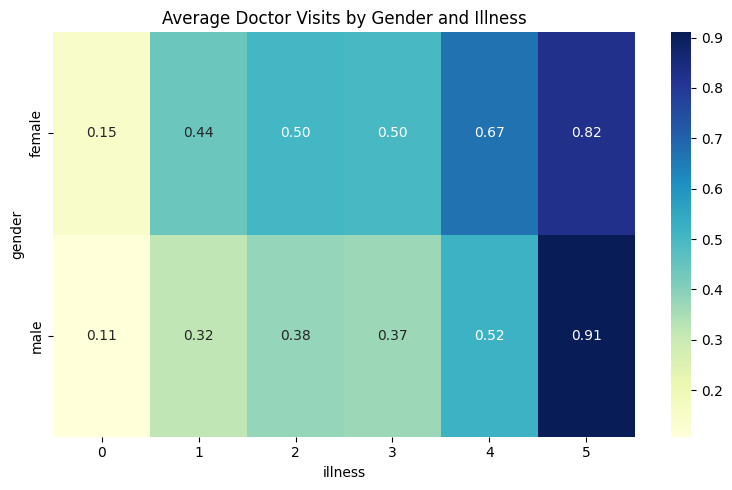

In [32]:
pivot = pd.pivot_table(
    df,
    values="visits",
    index="gender",
    columns="illness",
    aggfunc="mean",
    observed=True
)

print("Average Doctor Visits by Gender and Illness")
display(pivot.round(2))

plt.figure(figsize=(8, 5))

sns.heatmap(
    pivot,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu"
)

plt.title("Average Doctor Visits by Gender and Illness")
plt.tight_layout()
plt.show()

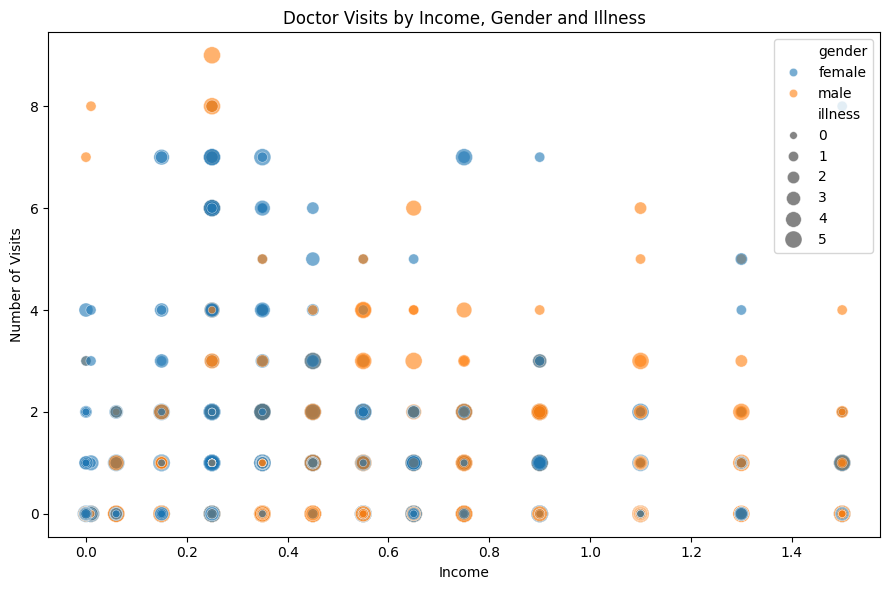

In [33]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x="income",
    y="visits",
    hue="gender",
    size="illness",
    sizes=(30, 150),
    alpha=0.6
)

plt.title("Doctor Visits by Income, Gender and Illness")
plt.xlabel("Income")
plt.ylabel("Number of Visits")
plt.tight_layout()
plt.show()

**Key findings:**

 1. The distribution of doctor visits among patients.

2. The presence of skewness and potential outliers.

3. Differences in doctor visits across age and gender groups.

4. Relationships between illness measures and doctor visit frequency.

5. Differences in visit patterns across income and insurance groups.

6. Combined patterns involving chronic conditions and other patient characteristics.

7. Correlations among numerical variables.

**Recommendations:**

Based on the patterns observed in the dataset, the following areas can be considered for further investigation:

1. Examine differences in healthcare utilization across demographic groups.

2. Study visit patterns among patients reporting chronic conditions.

3. Investigate whether income and insurance status are associated with differences in doctor visits.

4. Examine patients reporting zero visits to understand how their characteristics differ from those reporting visits.

5. Use multiple patient characteristics when interpreting healthcare utilization patterns.

6. Collect additional information about healthcare access, medical costs and patient outcomes to support more detailed future analysis.

**Limitations**

* The analysis depends on the variables available in the dataset.

* Variable units and category encodings must be verified.

* Missing or unusual values may affect the results.

* Correlation does not establish causation.

* Differences between groups may be influenced by other unobserved characteristics.

* Doctor visit frequency alone does not measure healthcare quality or patient outcomes.

* Findings from this dataset may not generalize to all populations or healthcare systems.

**Conclusion:**

  This project demonstrates the use of Python-based data analytics to examine doctor visit patterns using healthcare data. Univariate analysis provides an understanding of individual variables, bivariate analysis explores relationships between pairs of variables, and multivariate analysis investigates combined patterns across several patient characteristics.

The use of descriptive statistics, visualizations, group comparisons and correlation analysis helps convert raw data into interpretable information. The findings can support further investigation of healthcare utilization and assist in identifying areas that may deserve additional attention.

Overall, the project provides practical experience in data cleaning, exploratory data analysis, statistical summarization and data visualization. The results are intended to describe patterns within the available dataset and should not be interpreted as evidence of causal relationships.